In [1]:
from solver.utils.gmsh_function import *
from solver.utils.file_path import *
from solver.src.radiation_algorithm.radiation_algorithm import *

from solver.efield.efield1 import *
from solver.efield.efield2 import radiation_intensity_distribution_over_sphere_surface
from solver.efield.efield3 import antenna_directivity_pattern

from solver.utils.frequency_sweep import *

In [2]:
name = "radiate_bowtie_gmsh"
path = setup_save_file_paths(name)

In [ ]:
# Bowtie antenna parameters
width = 0.5        # Total width
hight = 1.0        # Total height
width_finite = 0.1 # Width of the feed line
hight_up = 2.0
feed_point = [0, 0, 0]
model_name  = "bowtie_antenna"

initial_mesh_size = width_finite

gmsh.initialize()
gmsh.model.add(model_name)
setup_performance_config()

# Definition of points
p0 = gmsh.model.occ.addPoint(-width/2, -hight/2, 0)
p1 = gmsh.model.occ.addPoint(-width_finite/2, 0, 0)
p2 = gmsh.model.occ.addPoint(-width/2, hight/2, 0)
p3 = gmsh.model.occ.addPoint(-width_finite/2, hight_up/2, 0)
p4 = gmsh.model.occ.addPoint(width_finite/2, hight_up/2, 0)
p5 = gmsh.model.occ.addPoint(width/2, hight/2, 0)
p6 = gmsh.model.occ.addPoint(width_finite/2, 0, 0)
p7 = gmsh.model.occ.addPoint(width/2, -hight/2, 0)
p8 = gmsh.model.occ.addPoint(width_finite/2, -hight_up/2, 0)
p9 = gmsh.model.occ.addPoint(-width_finite / 2, -hight_up / 2, 0)

# Creation of contour segments
l1 = gmsh.model.occ.addLine(p0, p1)
l2 = gmsh.model.occ.addLine(p1, p2)
l3 = gmsh.model.occ.addLine(p2, p3)
l4 = gmsh.model.occ.addLine(p3, p4)
l5 = gmsh.model.occ.addLine(p4, p5)
l6 = gmsh.model.occ.addLine(p5, p6)
l7 = gmsh.model.occ.addLine(p6, p7)
l8 = gmsh.model.occ.addLine(p7, p8)
l9 = gmsh.model.occ.addLine(p8, p9)
l10 = gmsh.model.occ.addLine(p9, p0)

cl = gmsh.model.occ.addCurveLoop([l1, l2, l3, l4, l5, l6, l7, l8, l9, l10])
bowtie = gmsh.model.occ.addPlaneSurface([cl])

generate_and_save_mesh(path, initial_mesh_size)

# gmsh.fltk.run()

gmsh.finalize()

[PERFORMANCE] Gmsh configured to utilize 16 threads.
Geometry file saved in data/gmsh_files/radiate_bowtie_gmsh.brep successfully
--- Starting Mesh Optimization (Dim: 2) ---
--- Optimization Complete ---
Mesh file saved in data/gmsh_files/radiate_bowtie_gmsh.msh successfully


In [7]:
frequency = 75e6

_ = radiation_algorithm(path, frequency, feed_point, excitation_unit_vector='y', gap_width=0.5*initial_mesh_size, voltage_amplitude=1, show=True, save_image=True)

Number of points: 114
Number of triangles: 176
Number of edges: 239
[calculate_z_matrice] Using GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) for the impedance matrix assembly (239x239 edges).
Total input power P_in = 0.5*Re(V·I*) = 1.173243e-02 W
Port 0: P_in = 1.1732e-02 W  |  Q_in = 3.5907e-03 VAR  |  Z_in = 38.9671+11.9257j Ohm



Image saved in PDF format: data/fig_image/radiate_bowtie_gmsh_antenna_surface_current_in_radiation_mode.pdf



In [8]:
print("Calculating radiation intensity distribution over sphere surface...")
radiation_intensity_distribution_over_sphere_surface(path, save_image=True)

Calculating radiation intensity distribution over sphere surface...
Hollow sphere loaded: 5150 points, 10296 triangles.

[Antenna Results]
  Total Radiated Power : 0.011206006419891097 W
  Gain : 1.6617 (2.21 dBi)

[Power Budget]
  P_in  (0.5*Re(V·I*)) = 1.173243e-02 W
  P_rad (sphere integ.) = 1.120601e-02 W
  Raw efficiency       = 95.5131 %
  Port 0: Z_in = 38.9671+11.9257j Ω  |  R_in = 38.9671 Ω
  Total Efficiency     = 95.51 %
Data saved successfully to data/antennas_gain_power/radiate_bowtie_gmsh_gain_power.mat


Image saved: data/fig_image/radiation_pattern_radiate_bowtie_gmsh.pdf


Generating antenna directivity pattern...
Data loaded from data/antennas_gain_power/radiate_bowtie_gmsh_gain_power.mat


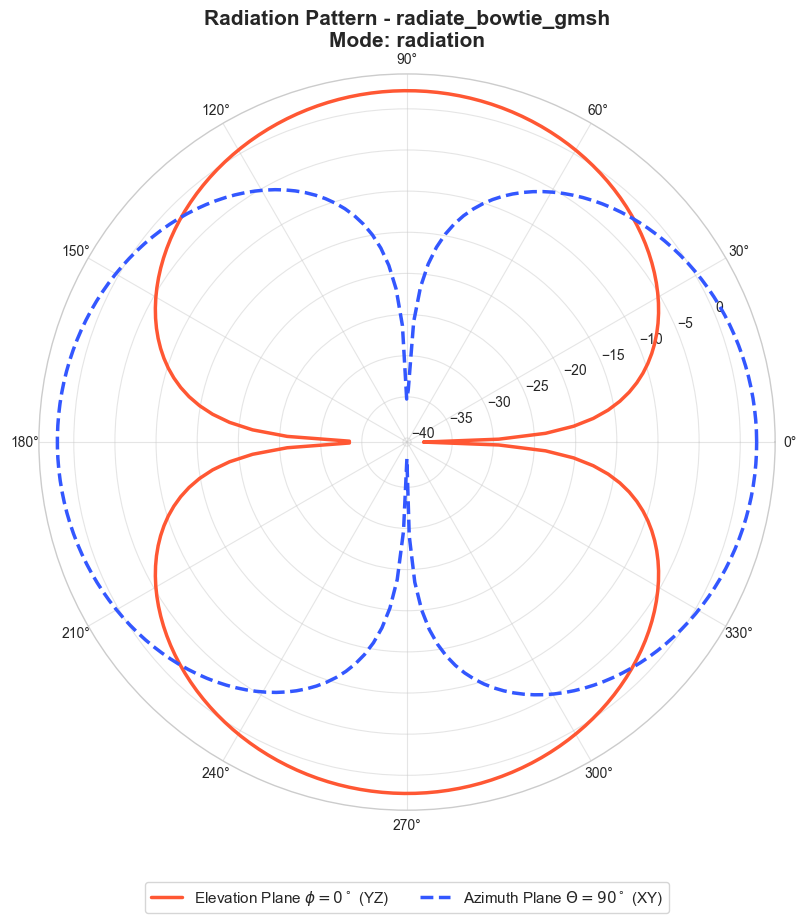

In [9]:
print("Generating antenna directivity pattern...")
antenna_directivity_pattern(path, mode='radiation', save_image=True)

In [12]:
freq_start = 50e6
freq_stop  = 120e6
frequency_sweep(path, freq_start, freq_stop, feed_point, excitation_unit_vector='y', gap_width=0.5*initial_mesh_size, n_points=41, show=False)

MULTIPLE PORT FREQUENCY SWEEP CONFIGURATION
Number of Ports detected: 1
  > Port 0 | Location: [0 0 0] | Phase Offset:   0.00°
Range: 50.00 MHz to 120.00 MHz (41 points)

Mesh ready: 114 points, 176 triangles, 239 edges

Assembling Z(f) for 41 frequencies (239x239 edges) on GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) -- geometry reused across the whole sweep...
[calculate_z_matrice_sweep] Using GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) for the impedance matrix assembly (239x239 edges, 41 frequencies).
Z(f) assembly done in 45.7 s (1.114 s/frequency amortised)

Step 1/41 |   50.00 MHz | P0: -3.00dB
Step 2/41 |   51.75 MHz | P0: -3.51dB
Step 3/41 |   53.50 MHz | P0: -4.10dB
Step 4/41 |   55.25 MHz | P0: -4.77dB
Step 5/41 |   57.00 MHz | P0: -5.53dB
Step 6/41 |   58.75 MHz | P0: -6.37dB
Step 7/41 |   60.50 MHz | P0: -7.30dB
Step 8/41 |   62.25 MHz | P0: -8.31dB
Step 9/41 |   64.00 MHz | P0: -9.39dB
Step 10/41 |   65.75 MHz | P0: -10.51dB
Step 11/41 |   67.50 MHz | P0: -11.63dB
Step 12/41 | 

Figure exported to: data/fig_image/S_Parameters_AllPorts_radiate_bowtie_gmsh.pdf


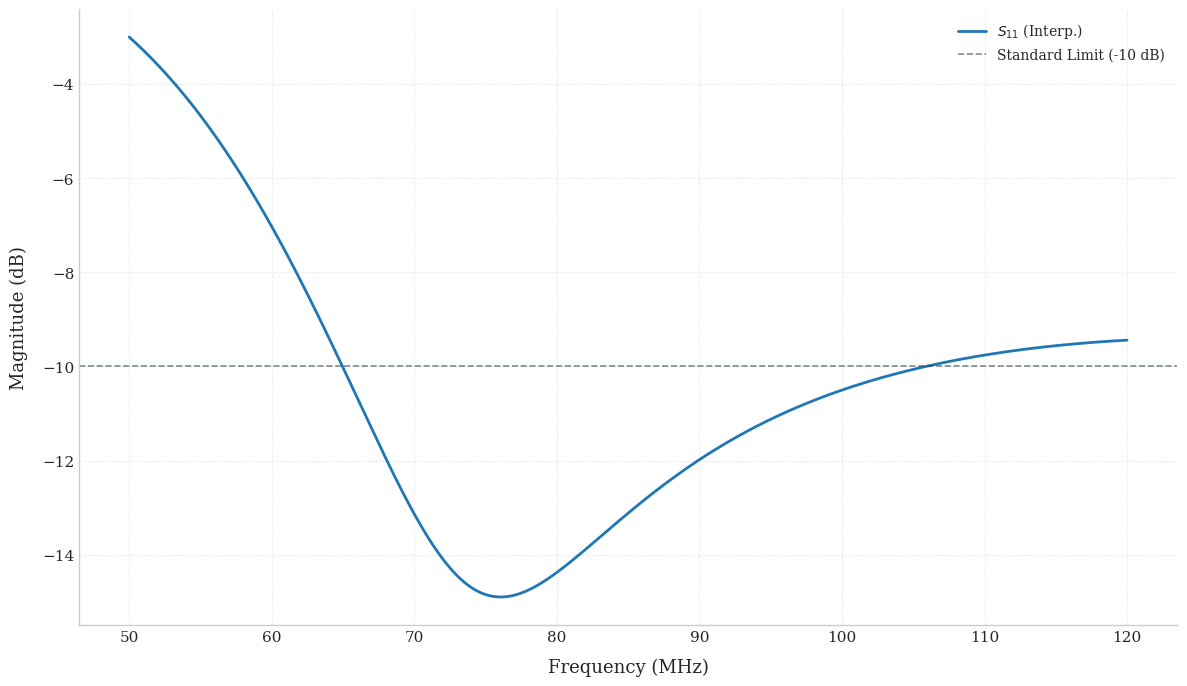

In [13]:
plot_s_parameters(path, interpolation_threshold=0, save_pdf=True, save_folder="data/fig_image/")